# Phase 4: a small masked diffusion model on 9×9 Sudoku

This notebook walks through phase 4 in the order it was run.

- Every cell loads committed tables and figures from `results/phase4/`. No model is loaded and nothing is trained here.
- Every number traces back to a command in `experiments/4.x/README.md`. Each README has the predictions committed before the run and a check of each one afterwards; about half did not hold.
- The summary with limits is `results/phase4/SUMMARY.md`.

One 1.86M-parameter model family, one puzzle generator, one laptop. Nothing here is a new method. Unless stated, numbers are the share of the 667 hard test puzzles filled with a rule-valid grid; brackets are 95% bootstrap intervals over puzzles.

In [1]:
import os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, Markdown, display
R = Path("results/phase4")
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)

def show(exp, table, image=None, cols=None, query=None):
    df = pd.read_csv(R / exp / table)
    if query:
        df = df.query(query)
    display(df[cols] if cols else df)
    if image:
        display(Image(R / exp / image))

def hard_test(path):
    d = pd.read_csv(R / path)
    return d[d.band == "hard"].set_index("sampler_steps").valid

## 4.0 and 4.1 Data, then supervised training to a plateau

100,002 train puzzles in three difficulty bands by number of blanks, from a local generator, with a data report that had to pass before training. The model was then trained on stored solutions with the masked diffusion loss at a constant learning rate of 3e-4 until a plateau rule stopped it at step 43,546 (4 h 58 min).

**Shows:** unlike the converged 4×4 toy, the number of sampler steps matters a lot here.
**Does not show:** convergence in solve rate. The constant learning rate comes back at the end of this notebook.

# Phase 4, step 4.0: data report

Built by `python -m phase4.analysis data` from the cache in `~/dllm-cache/phase4` (generator seed 0, scale 1.0). Report time: 3 s.

## Gate

| check | result | note |
|---|---|---|
| Every stored solution is valid, agrees with the givens, and is the only solution (all val and test, 5,000 train) | PASS |  |
| No solution shared across splits, also after digit relabelling; no duplicates inside a split | PASS |  |
| Digit frequency per position consistent with 1/9 | PASS | largest deviation 3.85 standard errors |
| Hidden cells spread evenly over the 81 positions in every band | PASS | largest deviation below 4.5 standard errors in every band |
| Bands differ in difficulty (share solved by naked singles drops by more than 10 points per band) | PASS |  |
| The hard band contains puzzles that singles do not solve | PASS | 32.1% of test |
| "Repeat until stuck" does not solve everything in every band | PASS | easy 99.4%; medium 76.6%; hard 10.5% |

**Gate: PASS.** Training may start.

Limit of this dataset: puzzles come from hiding random cells of random grids. They are easier than curated hard collections, and the difficulty classes use only two solving techniques, so "needs more" is a mixed bag.


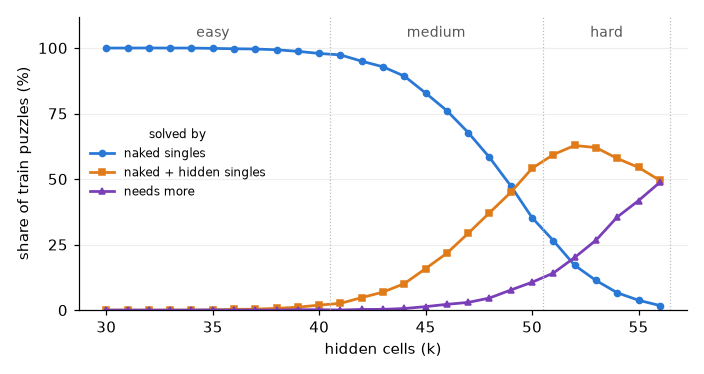

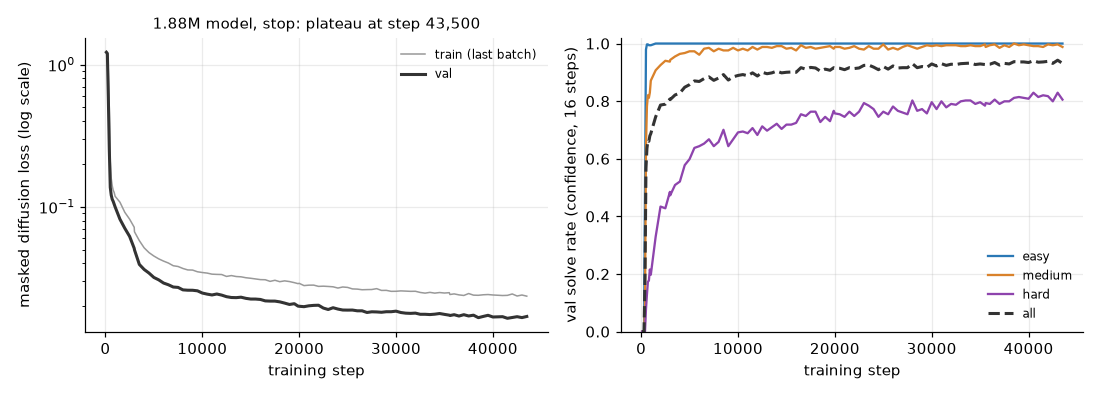

,split,sampler_steps,band,n,valid,lo,hi
0,test,4,easy,667,1.000,1.000,1.000
1,test,4,medium,667,0.957,0.940,0.972
2,test,4,hard,667,0.535,0.499,0.573
3,test,16,easy,667,1.000,1.000,1.000
4,test,16,medium,667,0.996,0.990,1.000
5,test,16,hard,667,0.814,0.786,0.841
6,test,81,easy,667,0.999,0.996,1.000
7,test,81,medium,667,0.999,0.996,1.000
8,test,81,hard,667,0.871,0.846,0.895


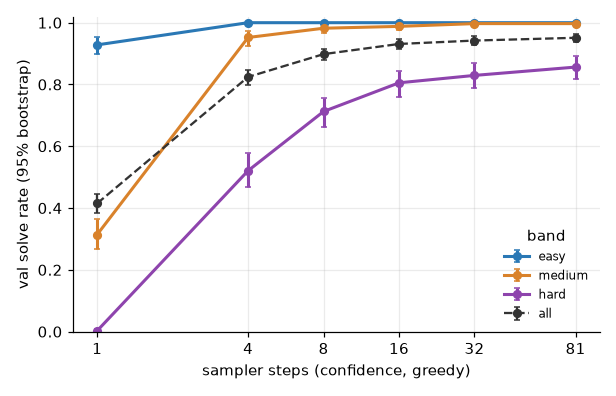

In [2]:
display(Markdown("\n## ".join((R / "data_report.md").read_text().split("\n## ")[:2])))
display(Image(R / "data_difficulty_by_k.png"))
display(Image(R / "sft" / "sft_training_curve.png"))
show("sft", "sft_valid_test.csv", "sft_solve_by_steps.png")

## 4.2 Unmasking order

The same weights, different rules for which cells to commit first.

**Shows:** order by confidence solves 0.81 of the hard band at 16 steps, a random order 0.13. A perfect order would solve every puzzle with the same weights.
**Does not show:** why confidence orders well while ranking wrong cells badly (the calibration table below).

,band,strategy,1,4,8,16,32,81
8,hard,confidence,0.003,0.535,0.736,0.814,0.849,0.871
9,hard,entropy,0.003,0.528,0.742,0.813,0.852,0.876
10,hard,margin,0.003,0.544,0.736,0.813,0.844,0.865
11,hard,random,0.003,0.029,0.085,0.128,0.163,0.210


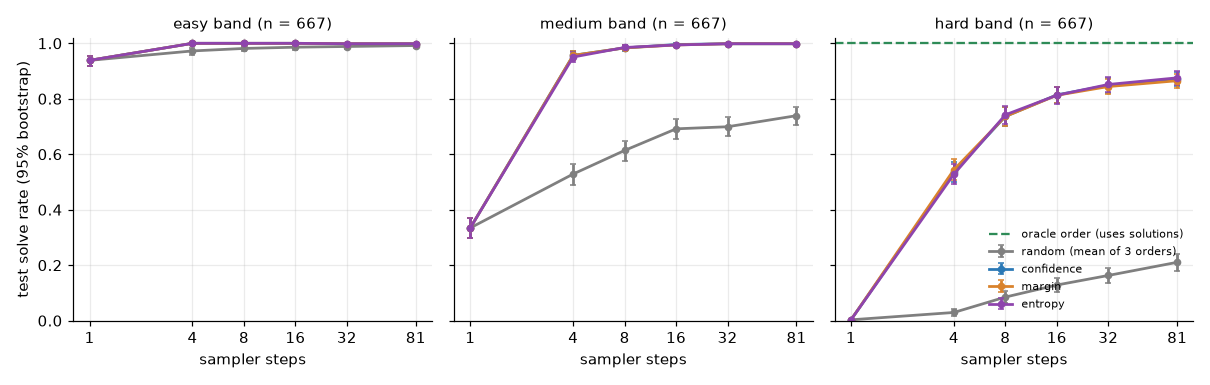

,band,steps,solve_rate,cell_acc,mean_cell_conf,cell_ece,cell_auroc
0,all,16,0.937,0.970,0.998,2.797e-02,0.736
1,easy,16,1.000,1.000,1.000,4.768e-07,NaN
2,medium,16,0.996,0.998,1.000,1.635e-03,0.768
3,hard,16,0.814,0.926,0.995,6.871e-02,0.579


In [3]:
show("4.2", "strategies_table.csv", "strategies.png", query="band == 'hard'")
show("4.2", "calibration.csv", cols=["band", "steps", "solve_rate", "cell_acc", "mean_cell_conf", "cell_ece", "cell_auroc"])

## 4.3 and 4.4 The phase 3 objectives on 9×9

RL starts from the plateau model on hard puzzles with 4 sampler steps (solve rate 0.535), 500 steps at lr 1e-5, three seeds.

**Shows:** only the objectives that pull valid rollouts up gain; plain wd1 ends below the start.
**Does not show:** that RL improves this model. 4.9e and 4.9f below: the supervised model simply continued at lr 1e-5 gains more than any row here. The table still orders the objectives against each other.

,method,n_seeds,test_mean,test_std,test_minus_start,test_minus_start_lo,test_minus_start_hi,test_ref_minus_start
0,wd1 (τ=1),3,0.505,0.014,-0.030,-0.058,-0.004,-0.022
1,"wd1, floored",3,0.549,0.008,0.013,-0.009,0.037,0.009
2,wd1 + KL to start,3,0.544,0.011,0.009,-0.011,0.029,0.012
3,d1-style GRPO,3,0.554,0.006,0.018,-0.002,0.037,0.015
4,positive-only (w⁻=0),3,0.590,0.012,0.054,0.031,0.079,0.021
5,filtered imitation,3,0.586,0.015,0.051,0.025,0.078,0.021
6,"self-training, SFT loss",3,0.602,0.010,0.067,0.038,0.095,0.022


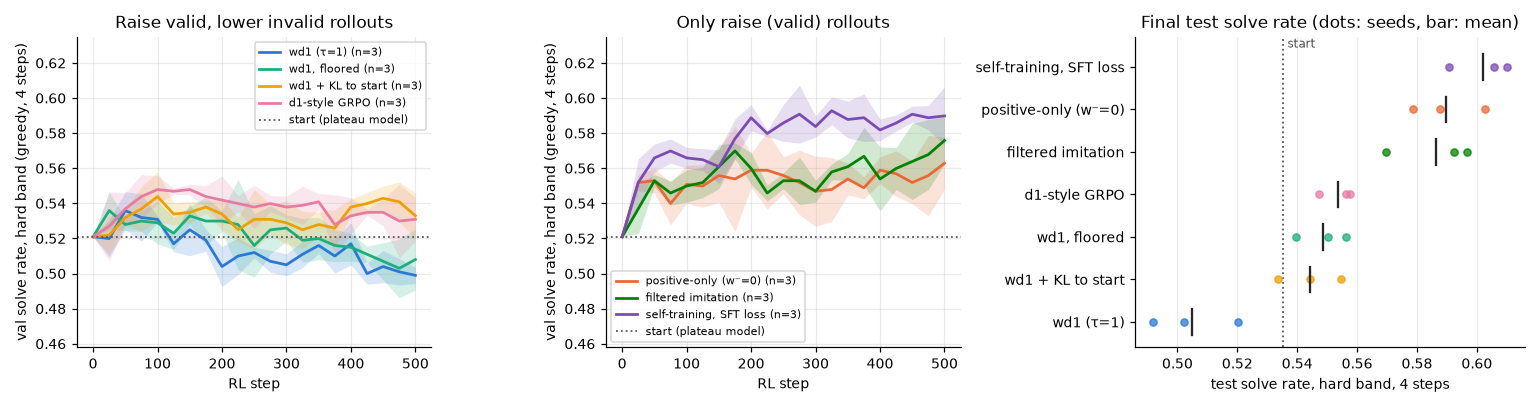

In [4]:
show("4.4", "summary.csv", "objectives.png", ["method", "n_seeds", "test_mean", "test_std", "test_minus_start", "test_minus_start_lo", "test_minus_start_hi", "test_ref_minus_start"])

## 4.4b, 4.5b, 4.6b Where rollouts fail, and whether errors can be erased

**Shows:** a failed grid is one or two early wrong cells followed by cells that fit them. If the wrong cells are known, masking and re-predicting them solves 0.91 at 4 passes. With any score available without the solution, remasking gains at most 0.02. A detector would need to find about nine wrong cells in ten; a linear readout of the frozen model finds six.
**Does not show:** that no detector can be learned; none was trained beyond a linear probe.

In [5]:
show("4.4b", "error_structure.csv")
show("4.5b", "remask.csv", query="model == 'start'")
show("4.6b", "degraded_oracle.csv")
show("4.6b", "probes.csv")

,sampler_steps,n_puzzles,failed,wrong_cells,wrong_cells_per_failed_puzzle,wrong_at_first_error_step_mean,wrong_after_first_error_step_mean,share_of_wrong_cells_after_first_error_step,first_error_step_mean,first_step_wrong_cells_visible_conflict,first_step_wrong_cells_same_step_conflict,first_step_wrong_cells_no_conflict,failed_puzzles_with_visible_conflict,failed_puzzles_with_same_step_conflict,failed_puzzles_with_no_conflict,solved_but_not_stored_solution
0,4,667,310,5065,16.339,1.903,14.435,0.883,0.684,0.0,0.083,0.917,0.0,0.129,0.948,0
1,16,667,124,2637,21.266,1.323,19.944,0.938,3.871,0.0,0.006,0.994,0.0,0.008,0.992,0


,model,forward_passes,fix_rounds,arm,solve,minus_plain,lo,hi,cells_remasked
0,start,4,0,plain,0.535,0.000,0.000,0.000,0.000
1,start,4,0,rcr,0.549,0.013,-0.002,0.029,7.793
2,start,4,1,fix_lowconf,0.457,-0.078,-0.111,-0.046,11.184
3,start,4,1,fix_conflict,0.463,-0.072,-0.105,-0.037,4.403
4,start,4,1,fix_oracle,0.907,0.372,0.336,0.408,8.958
5,start,8,0,plain,0.736,0.000,0.000,0.000,0.000
6,start,8,0,rcr,0.750,0.013,-0.004,0.032,28.576
7,start,8,2,fix_lowconf,0.669,-0.068,-0.096,-0.037,11.184
8,start,8,2,fix_conflict,0.670,-0.066,-0.095,-0.036,1.738
9,start,8,2,fix_oracle,1.000,0.264,0.231,0.297,3.500


,forward_passes,fix_rounds,arm,rho,phi,solve,plain,minus_plain,lo,hi
0,4,1,degraded_oracle,0.5,0.0,0.442,0.535,-0.093,-0.126,-0.060
1,4,1,degraded_oracle,0.5,0.1,0.445,0.535,-0.090,-0.124,-0.057
2,4,1,degraded_oracle,0.5,0.3,0.444,0.535,-0.091,-0.126,-0.059
3,4,1,degraded_oracle,0.5,0.6,0.442,0.535,-0.093,-0.126,-0.060
4,4,1,degraded_oracle,0.7,0.0,0.454,0.535,-0.081,-0.114,-0.050
5,4,1,degraded_oracle,0.7,0.1,0.456,0.535,-0.080,-0.112,-0.046
6,4,1,degraded_oracle,0.7,0.3,0.457,0.535,-0.078,-0.111,-0.045
7,4,1,degraded_oracle,0.7,0.6,0.453,0.535,-0.083,-0.115,-0.051
8,4,1,degraded_oracle,0.9,0.0,0.577,0.535,0.042,0.004,0.076
9,4,1,degraded_oracle,0.9,0.1,0.552,0.535,0.017,-0.019,0.052


,fill_steps,pass,inputs,train_cells,wrong_share_test,auroc_all_cells,auroc_failed_grids,recall_rho,false_alarm_phi
0,3,visible,features+probs,160289,0.167,0.754,0.636,0.601,0.220
1,3,visible,probs only,160289,0.167,0.542,0.532,0.256,0.232
2,3,leave_out,features+probs,160289,0.167,0.763,0.639,0.576,0.193
3,3,leave_out,probs only,160289,0.167,0.611,0.587,0.213,0.031
4,6,visible,features+probs,160289,0.117,0.760,0.594,0.618,0.213
5,6,visible,probs only,160289,0.117,0.533,0.524,0.469,0.446
6,6,leave_out,features+probs,160289,0.117,0.773,0.598,0.600,0.174
7,6,leave_out,probs only,160289,0.117,0.585,0.561,0.149,0.011


## 4.5a, 4.6a, 4.6c, 4.6d Taking the objectives apart

- 4.5a: a sampled unmasking order gives more unequal-reward groups and no gain; weights over the batch reach the level of filtered imitation.
- 4.6a: the pull-up objectives are nearly orthogonal to the exact score-function gradient of the solve rate and gain as much as a step along it.
- 4.6c: no single factor (batch weights, one inner step, the paper's optimiser values, dense reward, lower success rate) makes the push-down term of wd1 pay.
- 4.6d: supervised steps on the same puzzles give the same gain as self-training, whichever puzzles carry the loss.

All four start from the constant-lr model, so the caveat of 4.4 applies to them too.

,a,b,sampler_steps,a_minus_b,lo,hi
0,floored + sampled order,"wd1, floored",4,-0.002,-1.800e-02,1.500e-02
1,floored + sampled order,"wd1, floored",16,-0.006,-2.100e-02,8.500e-03
2,floored + batch weights,"wd1, floored",4,0.030,1.200e-02,5.000e-02
3,floored + batch weights,"wd1, floored",16,-0.001,-1.750e-02,1.550e-02
4,floored + both,"wd1, floored",4,0.024,3.500e-03,4.400e-02
5,floored + both,"wd1, floored",16,0.011,-4.500e-03,2.650e-02
6,floored + both,floored + sampled order,4,0.025,7.500e-03,4.300e-02
7,floored + both,floored + sampled order,16,0.017,1.500e-03,3.250e-02
8,floored + both,floored + batch weights,4,-0.007,-2.050e-02,6.500e-03
9,floored + both,floored + batch weights,16,0.012,-5.000e-04,2.500e-02


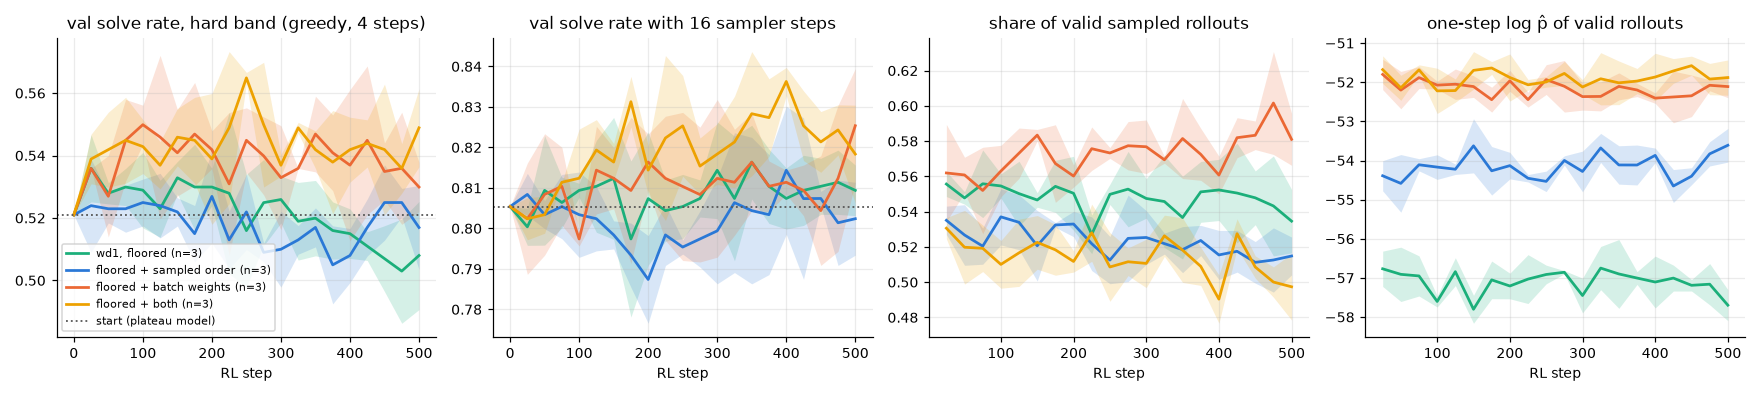

,model,objective,cos_with_gstar,J_gain_per_unit_step
0,start,pg_exact,0.818,0.612
1,start,pg_exact_group_baseline,0.205,0.154
2,start,pull_path_no_order_factor,-0.046,-0.034
3,start,pull_onestep_nomask,0.003,0.002
4,start,self_training,-0.013,-0.010
5,start,supervised_all,0.004,0.003
6,start,filtered,0.060,0.045
7,start,positive_only,0.079,0.059
8,start,wd1,-0.037,-0.028
9,start,wd1_push_down,-0.089,-0.067


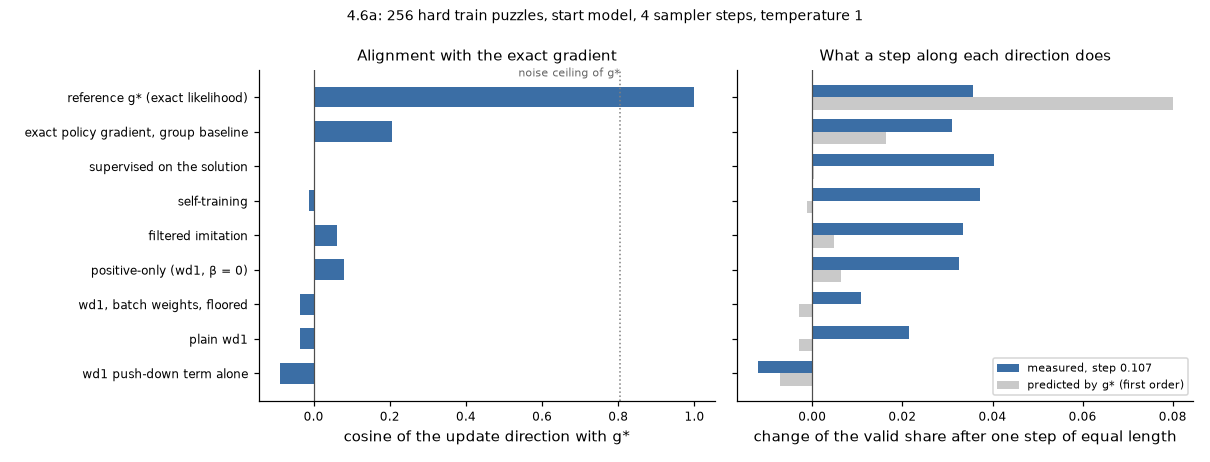

,a,b,sampler_steps,a_minus_b,lo,hi
0,wd1_beta0_tau1_batchw,wd1_beta1_floor-75.6_tau1_batchw,4,3.050e-02,0.008,0.052
1,wd1_beta0_tau1_batchw,wd1_beta1_floor-75.6_tau1_batchw,16,2.400e-02,0.004,0.043
2,wd1_beta0_tau1_batchw,self_diffusion,4,7.500e-03,-0.009,0.024
3,wd1_beta0_tau1_batchw,self_diffusion,16,1.000e-02,-0.004,0.024
4,wd1_beta0_tau1_batchw,wd1_beta0_tau1,4,2.000e-02,0.004,0.036
5,wd1_beta0_tau1_batchw,wd1_beta0_tau1,16,1.200e-02,0.000,0.025
6,wd1_beta1_tau1_mu1,wd1_beta1_tau1,4,3.050e-02,0.010,0.051
7,wd1_beta1_tau1_mu1,wd1_beta1_tau1,16,2.300e-02,0.007,0.038
8,wd1_beta1_tau1_paperopt,wd1_beta1_tau1,4,3.200e-02,0.012,0.054
9,wd1_beta1_tau1_paperopt,wd1_beta1_tau1,16,2.750e-02,0.011,0.043


,a,b,sampler_steps,a_minus_b,lo,hi
0,supervised,self_diffusion,4,0.007,-0.006,2.200e-02
1,supervised,self_diffusion,16,0.013,0.004,2.450e-02
2,supervised_onsolved,self_diffusion,4,0.005,-0.009,1.850e-02
3,supervised_onsolved,self_diffusion,16,0.003,-0.007,1.450e-02
4,supervised_onunsolved,self_diffusion,4,0.001,-0.015,1.800e-02
5,supervised_onunsolved,self_diffusion,16,0.015,0.003,2.800e-02
6,supervised,supervised_onsolved,4,0.003,-0.011,1.600e-02
7,supervised,supervised_onsolved,16,0.011,0.001,2.100e-02
8,supervised,supervised_onunsolved,4,0.006,-0.010,2.150e-02
9,supervised,supervised_onunsolved,16,-0.001,-0.013,1.050e-02


In [6]:
show("4.5a", "paired.csv", "factorial.png")
show("4.6a", "directions.csv", "audit.png", ["model", "objective", "cos_with_gstar", "J_gain_per_unit_step"])
show("4.6c", "arm_pairs.csv")
show("4.6d", "arm_pairs.csv")

## 4.8 No stored solutions: printed digits only, then a rule checker

Cold start (4.8a): hide some of the printed digits and train the model to put them back. No rollouts, no checker. Then two loops that keep the model's own checker-valid grids and train on them (`harvest`, `hindsight`), against a control that just continues the givens loss.

**Shows:** at 19,546 steps the loops are ahead of the control (three seeds, two control seeds). Continued to the supervised step count, the control catches up at every budget on test: a head start, not a higher end point.
**Does not show:** seed variance of the long runs (one each).

In [7]:
show("4.8c", "pooled_pairs_two_controls.csv")
show("4.8e", "long_pairs_test.csv")

,a,b,sampler_steps,band,a_valid,b_valid,a_minus_b,lo,hi,b_seed0,b_seed1
0,hindsight,givens (2 seeds),4,easy,1.000,0.994,0.006,0.002,0.012,0.994,0.994
1,harvest,givens (2 seeds),4,easy,1.000,0.994,0.006,0.002,0.012,0.994,0.994
2,hindsight,givens (2 seeds),4,medium,0.899,0.843,0.056,0.029,0.085,0.850,0.835
3,harvest,givens (2 seeds),4,medium,0.912,0.843,0.069,0.043,0.097,0.850,0.835
4,hindsight,givens (2 seeds),4,hard,0.362,0.222,0.141,0.107,0.175,0.210,0.234
5,harvest,givens (2 seeds),4,hard,0.339,0.222,0.118,0.081,0.156,0.210,0.234
6,hindsight,givens (2 seeds),16,easy,1.000,1.000,0.000,0.000,0.000,1.000,1.000
7,harvest,givens (2 seeds),16,easy,1.000,1.000,0.000,0.000,0.000,1.000,1.000
8,hindsight,givens (2 seeds),16,medium,0.980,0.979,0.001,-0.009,0.010,0.982,0.976
9,harvest,givens (2 seeds),16,medium,0.985,0.979,0.006,-0.004,0.018,0.982,0.976


,a,b,sampler_steps,band,n,a_valid,b_valid,a_minus_b,lo,hi
0,hindsight_long,givens_long,4,easy,667,0.999,0.997,0.002,-0.003,0.007
1,hindsight_long,givens_long,4,medium,667,0.928,0.925,0.003,-0.018,0.025
2,hindsight_long,givens_long,4,hard,667,0.423,0.438,-0.015,-0.054,0.024
3,hindsight_long,givens_long,16,easy,667,1.000,1.000,0.000,0.000,0.000
4,hindsight_long,givens_long,16,medium,667,0.984,0.981,0.003,-0.009,0.015
5,hindsight_long,givens_long,16,hard,667,0.777,0.780,-0.003,-0.037,0.032
6,hindsight_long,givens_long,81,easy,667,1.000,1.000,0.000,0.000,0.000
7,hindsight_long,givens_long,81,medium,667,0.991,0.993,-0.002,-0.011,0.007
8,hindsight_long,givens_long,81,hard,667,0.835,0.850,-0.015,-0.048,0.017
9,sft,givens_long,4,easy,667,1.000,0.997,0.003,0.000,0.007


## 4.9 The learning rate

The three long models, each continued with its own training for 4,000 steps at lr 1e-5 instead of 3e-4, and nothing else changed.

**Shows:** all three gain, the supervised one most (+0.099 at 4 steps). Like for like, stored solutions are worth 0.14 at 4 steps, 0.07 at 16 and nothing at 81.
**Does not show:** an end point (the supervised model was still improving), a tuned schedule, or seed variance.

sampler_steps,4,16,81
"hard test band, valid share at N sampler steps",,,
"supervised, lr 3e-4",0.535,0.814,0.871
"supervised, then lr 1e-5",0.634,0.874,0.897
"givens only, lr 3e-4",0.438,0.780,0.850
"givens only, then lr 1e-5",0.495,0.807,0.895
"hindsight loop, lr 3e-4",0.423,0.777,0.835
"hindsight loop, then lr 1e-5",0.472,0.783,0.870


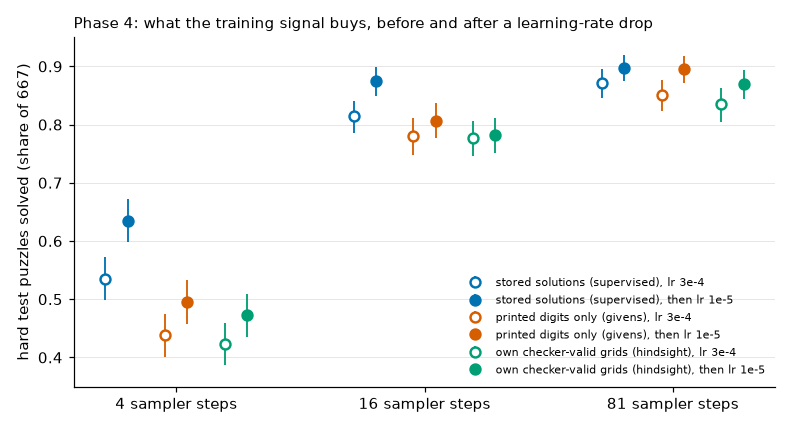

,band,a,b,sampler_steps,a_test,b_test,a_minus_b,lo,hi
0,hard,sft_lr1e-5,sft,4,0.634,0.535,0.099,0.068,0.129
1,hard,givens_lr1e-5,sft_lr1e-5,4,0.495,0.634,-0.139,-0.177,-0.102
2,hard,hindsight_lr1e-5,sft_lr1e-5,4,0.472,0.634,-0.162,-0.201,-0.124
3,hard,sft_lr1e-5,sft,16,0.874,0.814,0.060,0.037,0.083
4,hard,givens_lr1e-5,sft_lr1e-5,16,0.807,0.874,-0.068,-0.096,-0.039
5,hard,hindsight_lr1e-5,sft_lr1e-5,16,0.783,0.874,-0.091,-0.123,-0.061
6,hard,sft_lr1e-5,sft,81,0.897,0.871,0.025,0.003,0.050
7,hard,givens_lr1e-5,sft_lr1e-5,81,0.895,0.897,-0.002,-0.025,0.022
8,hard,hindsight_lr1e-5,sft_lr1e-5,81,0.870,0.897,-0.027,-0.052,-0.002


In [8]:
rows = {"supervised, lr 3e-4": "sft/sft_valid_test.csv", "supervised, then lr 1e-5": "4.9e/sft_lr1e-5_valid_test.csv",
        "givens only, lr 3e-4": "4.8e/givens_long_valid_test.csv", "givens only, then lr 1e-5": "4.9d/givens_lr1e-5_valid_test.csv",
        "hindsight loop, lr 3e-4": "4.8d/hindsight_long_valid_test.csv", "hindsight loop, then lr 1e-5": "4.9d/hindsight_lr1e-5_valid_test.csv"}
display(pd.DataFrame({k: hard_test(v) for k, v in rows.items()}).T.rename_axis("hard test band, valid share at N sampler steps"))
display(Image(R / "overview_hard_test.png"))
show("4.9e", "pairs.csv", query="band == 'hard'")

## 4.9f Self-training again, from the model that had the drop

The 4.4 self-training step and a supervised control, from `sft_lr1e-5`.

**Shows:** neither adds anything at 4 steps; self-training costs 0.03 at 16. The +0.067 of 4.4 is accounted for by the low learning rate of the RL step.
**Does not show:** that training on own valid grids can never help (one start, one learning rate, 500 steps).

In [9]:
show("4.9f", "pairs.csv")

,a,b,sampler_steps,a_test,b_test,a_minus_b,lo,hi,a_seed0,a_seed1,a_seed2
0,self,sft_lr1e-5,4,0.630,0.634,-0.004,-2.650e-02,0.017,0.636,0.618,0.636
1,sup,sft_lr1e-5,4,0.633,0.634,-0.002,-2.100e-02,0.021,0.637,0.625,0.636
2,self,sup,4,0.630,0.633,-0.003,-1.600e-02,0.010,0.636,0.618,0.636
3,self,self of 4.4,4,0.630,0.602,0.028,1.000e-02,0.045,0.636,0.618,0.636
4,self of 4.4,sft,4,0.602,0.535,0.067,3.800e-02,0.095,NaN,NaN,NaN
5,sft_lr1e-5,self of 4.4,4,0.634,0.602,0.032,1.100e-02,0.051,NaN,NaN,NaN
6,self,sft_lr1e-5,16,0.846,0.874,-0.028,-4.650e-02,-0.011,0.846,0.841,0.852
7,sup,sft_lr1e-5,16,0.862,0.874,-0.013,-3.050e-02,0.005,0.861,0.862,0.862
8,self,sup,16,0.846,0.862,-0.015,-2.700e-02,-0.004,0.846,0.841,0.852
9,self,self of 4.4,16,0.846,0.837,0.009,-3.500e-03,0.024,0.846,0.841,0.852


## 4.9g and 4.9h Closing checks

4.9g: plain wd1 and positive-only wd1 from `sft_lr1e-5`, to see whether the one sign that 4.4 still supports (push-down hurts, pull-up does not) holds without the free gain. 4.9h: the 500-step pass on own valid grids from `givens_lr1e-5`, to see whether the checker adds anything to the label-free model after its drop.

**Shows:** plain wd1 loses 0.077 at 4 steps, the same code without the push-down term 0.012. On the label-free model the pass on own valid grids still adds 0.033 at 4 steps and nothing at 16.
**Does not show:** that the 0.033 comes from the checker (no control arm from that start; the run was interrupted and resumed, see its README), or that no bounded push-down term could work from this start (not rerun).

In [10]:
show("4.9g", "pairs.csv")
show("4.9h", "pairs.csv")

,a,b,sampler_steps,a_test,b_test,a_minus_b,lo,hi,a_seed0,a_seed1,a_seed2
0,wd1,sft_lr1e-5,4,0.557,0.634,-0.077,-0.105,-0.051,0.558,0.552,0.562
1,pos,sft_lr1e-5,4,0.622,0.634,-0.012,-0.033,0.009,0.634,0.621,0.612
2,pos,wd1,4,0.622,0.557,0.065,0.041,0.089,0.634,0.621,0.612
3,wd1,self (4.9f),4,0.557,0.630,-0.072,-0.098,-0.047,0.558,0.552,0.562
4,pos,self (4.9f),4,0.622,0.630,-0.007,-0.028,0.011,0.634,0.621,0.612
5,wd1,sup (4.9f),4,0.557,0.633,-0.075,-0.101,-0.051,0.558,0.552,0.562
6,wd1,sft_lr1e-5,16,0.824,0.874,-0.051,-0.071,-0.031,0.825,0.828,0.819
7,pos,sft_lr1e-5,16,0.855,0.874,-0.019,-0.035,-0.004,0.853,0.862,0.850
8,pos,wd1,16,0.855,0.824,0.032,0.013,0.049,0.853,0.862,0.850
9,wd1,self (4.9f),16,0.824,0.846,-0.022,-0.040,-0.004,0.825,0.828,0.819


,a,b,sampler_steps,a_test,b_test,a_minus_b,lo,hi,a_seed0,a_seed1,a_seed2
0,self,givens_lr1e-5,4,0.528,0.495,0.033,6.500e-03,0.059,0.537,0.528,0.519
1,self,self4 (4.9b),4,0.528,0.515,0.013,-5.500e-03,0.030,0.537,0.528,0.519
2,self,sft_lr1e-5,4,0.528,0.634,-0.106,-1.419e-01,-0.071,0.537,0.528,0.519
3,givens_lr1e-5,givens_long,4,0.495,0.438,0.057,2.400e-02,0.090,NaN,NaN,NaN
4,self,givens_long,4,0.528,0.438,0.090,5.550e-02,0.124,0.537,0.528,0.519
5,self,givens_lr1e-5,16,0.805,0.807,-0.002,-2.300e-02,0.021,0.804,0.807,0.805
6,self,self4 (4.9b),16,0.805,0.789,0.016,1.000e-03,0.032,0.804,0.807,0.805
7,self,sft_lr1e-5,16,0.805,0.874,-0.069,-9.550e-02,-0.043,0.804,0.807,0.805
8,givens_lr1e-5,givens_long,16,0.807,0.780,0.027,-1.500e-03,0.054,NaN,NaN,NaN
9,self,givens_long,16,0.805,0.780,0.025,-5.000e-04,0.052,0.804,0.807,0.805


## What phase 4 leaves

1. On 9×9, sampler steps and unmasking order matter; failures start from one or two early wrong cells.
2. No RL objective tested here beat a learning-rate drop on the supervised model.
3. The push-down term of wd1 never paid in any setting tried; from the best model it is the only clear effect of an RL objective, and it is a loss (4.9g).
4. A model trained only on printed digits gets within 0.14 / 0.07 / 0.00 of the supervised one at 4 / 16 / 81 steps; the rule checker gave a faster start and no higher end, apart from 0.03 at 4 steps from a last pass on own valid grids (4.9h).
5. Five readings were corrected by later runs, three of them by the same cause: models trained at a constant learning rate, followed by steps at a lower one.

Limits and the table of corrected readings: `results/phase4/SUMMARY.md`.